# Task 2 — Trends, and the spaghetti problem

This notebook uses the Gapminder dataset, which contains 142 countries over 12 years. The main challenge is to choose a representation that tells the real story without overwhelming the reader.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

path = Path('data') / 'gapminder.csv'
df = pd.read_csv(path)
df.head()


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


## 1) Messy chart on purpose
This is the bad version: one line per country with a legend. It looks busy and hides the main pattern.

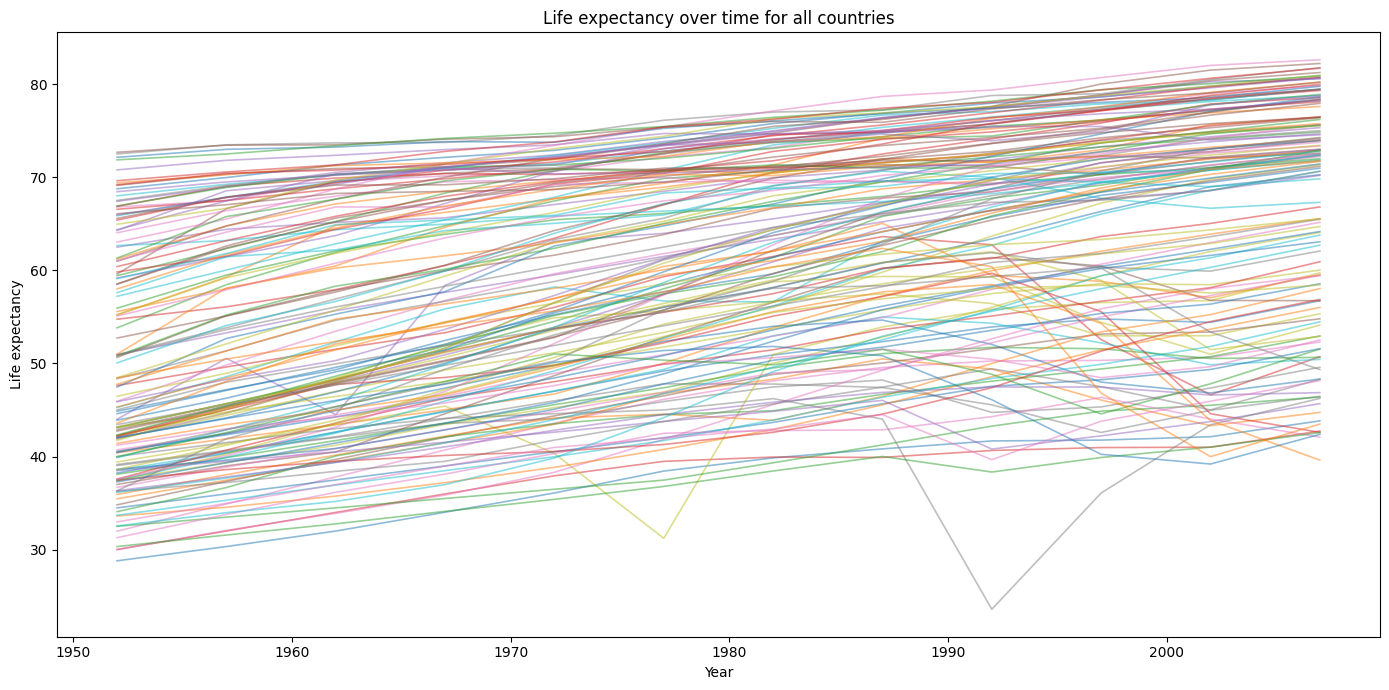

In [2]:
plt.figure(figsize=(14, 7))
for country, group in df.groupby('country'):
    plt.plot(group['year'], group['lifeExp'], alpha=0.5, linewidth=1.2)
plt.title('Life expectancy over time for all countries')
plt.xlabel('Year')
plt.ylabel('Life expectancy')
plt.tight_layout()
plt.show()


### What is wrong with this plot?
It has too many lines, no clear message, and the legend is unusable. A reader cannot see the main trend because the chart is trying to show every country at once.


## 2) Fix it by aggregation
A simpler view is to aggregate by continent so the trend becomes readable.

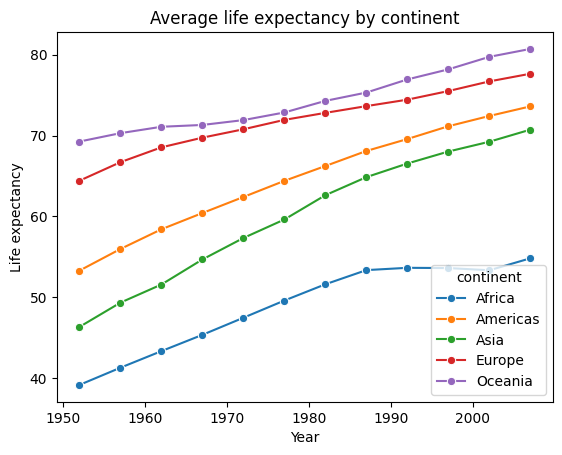

In [3]:
continent = df.groupby(['continent', 'year'], as_index=False)['lifeExp'].mean()

sns.lineplot(data=continent, x='year', y='lifeExp', hue='continent', marker='o')
plt.title('Average life expectancy by continent')
plt.xlabel('Year')
plt.ylabel('Life expectancy')
plt.show()


## 3) Fix it by highlighting
Keep all countries, but grey them out and highlight a few important ones.

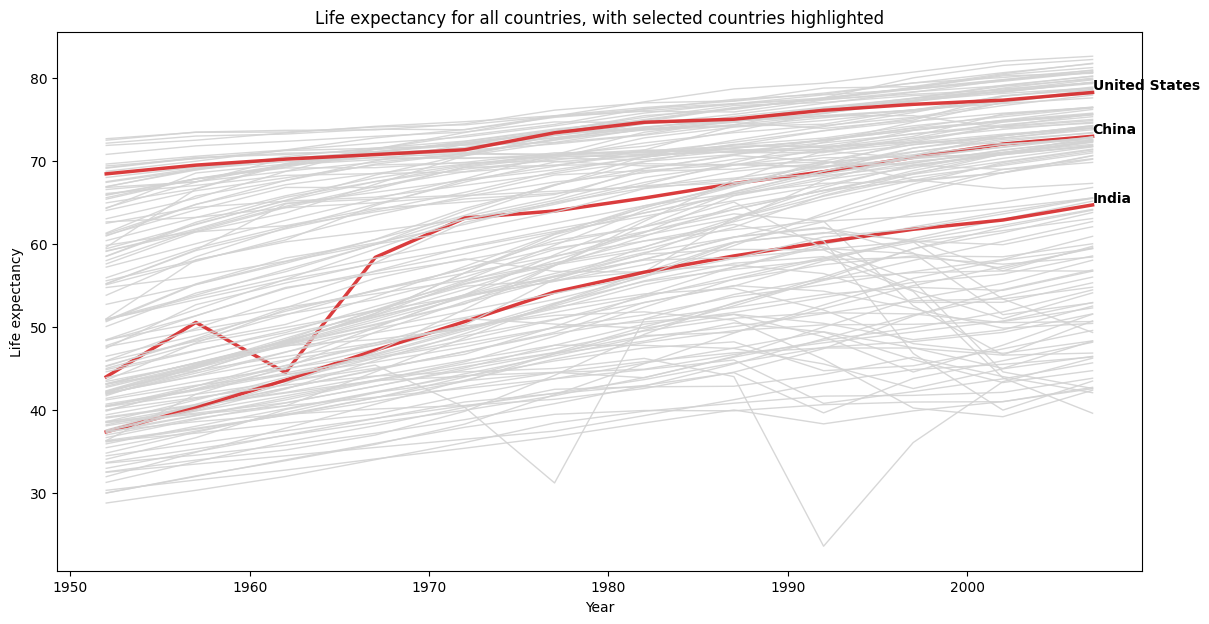

In [4]:
interesting = ['China', 'India', 'United States']
base = df.copy()
base['is_highlight'] = base['country'].isin(interesting)

plt.figure(figsize=(14, 7))
for country, group in base.groupby('country'):
    color = 'tab:red' if country in interesting else 'lightgray'
    lw = 2.5 if country in interesting else 1.0
    plt.plot(group['year'], group['lifeExp'], color=color, linewidth=lw, alpha=0.9)
    if country in interesting:
        last = group.sort_values('year').iloc[-1]
        plt.text(last['year'], last['lifeExp'], country, va='bottom', fontsize=10, fontweight='bold')

plt.title('Life expectancy for all countries, with selected countries highlighted')
plt.xlabel('Year')
plt.ylabel('Life expectancy')
plt.show()


### Compare the two fixes
Aggregation is best for showing the overall pattern across groups. Highlighting is better for showing exceptional countries without losing the context of all countries.


## 4) Final chart: has the gap narrowed?
The income gap is extremely skewed, so a log scale is helpful here. The chart compares the richest and poorest countries by year and shows whether the gap has closed.


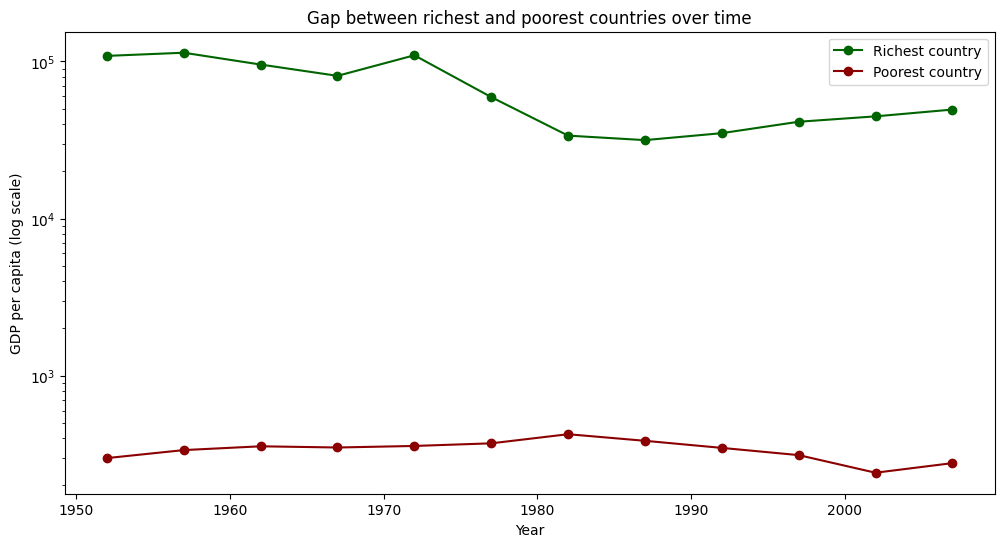

In [5]:
yearly = df.groupby('year').agg(
    richest=('gdpPercap', 'max'),
    poorest=('gdpPercap', 'min'),
    median=('gdpPercap', 'median')
).reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly['year'], yearly['richest'], label='Richest country', color='darkgreen', marker='o')
ax.plot(yearly['year'], yearly['poorest'], label='Poorest country', color='darkred', marker='o')
ax.set_yscale('log')
ax.set_title('Gap between richest and poorest countries over time')
ax.set_xlabel('Year')
ax.set_ylabel('GDP per capita (log scale)')
ax.legend()
plt.show()


The chart suggests that the absolute gap has not disappeared, but the relationship is easier to evaluate on a log scale because GDP per capita is highly skewed. This is a good example of choosing the view that matches the data distribution rather than forcing a raw linear scale.
